Step 1: Import the Dataset

Read TinyStories paper for detailed explanation.
Summary: Short stories consisted of words and sentences 3~4 year old kids can understand. It is generated by GPT4

In [ ]:
!pip install datasets

In [ ]:
pip install -U datasets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 44.7 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0


In [ ]:
from datasets import load_dataset

ds = load_dataset("roneneldan/TinyStories")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…):   0%|          | 0.00/249M [00:00<?, ?B/s]

data/train-00001-of-00004-5852b56a2bd28f(…):   0%|          | 0.00/248M [00:00<?, ?B/s]

data/train-00002-of-00004-a26307300439e9(…):   0%|          | 0.00/246M [00:00<?, ?B/s]

data/train-00003-of-00004-d243063613e5a0(…):   0%|          | 0.00/248M [00:00<?, ?B/s]

data/validation-00000-of-00001-869c898b5(…):   0%|          | 0.00/9.99M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Step 2: Tokenize the Dataset


(1) Tokenize the dataset into tokenIDs.

(2) Create a file called "train.bin" and "validtion.bin" where we will store the tokenIDs from the entire dataset.

(3) We make sure the tokenIDs are stored on a disk, rather than on the RAM for efficient computations.

In [ ]:
!pip install tiktoken
import tiktoken
import os
import numpy as np
from tqdm.auto import tqdm  ## library to create progess bars (see how much time is left when processing large datasets)


# tiktoken is a library which provides tokenizers from openAI, gpt2 uses BPE ##
## call the same vocab_list used in GPT2 then store it in 'enc'
enc = tiktoken.get_encoding("gpt2")

## you should determine the vocabulary size during BPE (vocab size (or number of 'repetition') should be passed to the BPE 'function' so that it knows when to stop merging)

def process(example):  # takes the encoder (BPE in this case) and converts every token into token ID ##
    ids = enc.encode_ordinary(example['text']) # encode_ordinary ignores any special tokens
    out = {'ids': ids, 'len': len(ids)}
    return out

if not os.path.exists("train.bin"):
    tokenized = ds.map(
        process,
        remove_columns=['text'],
        desc="tokenizing the splits",
        num_proc=8,
        )
    # concatenate all the ids in each dataset into one large file we can use for training
    ## instead of holding millions of numbers in RAM, we write them directly to a file on the hard drive using np.memmap (코와이네...)
    for split, dset in tokenized.items():
        arr_len = np.sum(dset['len'], dtype=np.uint64)
        filename = f'{split}.bin'
        dtype = np.uint16 # (can do since enc.max_token_value == 50256 is < 2**16, token id를 16bit짜리 정수형으로 저장한다는 것 같음; 메모리 아끼려고)
        arr = np.memmap(filename, dtype=dtype, mode='w+', shape=(arr_len,))
        total_batches = 1024  ## batch가 1024개래 ㄷㄷㄷ 개많네

        idx = 0
        for batch_idx in tqdm(range(total_batches), desc=f'writing {filename}'):
            # Batch together samples for faster write
            ## prevents RAM crash. instead of loading the whole dataset, it takes small slice (shard) of the dataset of it
            batch = dset.shard(num_shards=total_batches, index=batch_idx, contiguous=True).with_format('numpy')
            arr_batch = np.concatenate(batch['ids'])
            # Write into mmap
            arr[idx : idx + len(arr_batch)] = arr_batch
            idx += len(arr_batch)
        arr.flush()

tokenizing the splits (num_proc=8):   0%|          | 0/2119719 [00:00<?, ? examples/s]

tokenizing the splits (num_proc=8):   0%|          | 0/21990 [00:00<?, ? examples/s]

writing train.bin:   0%|          | 0/1024 [00:00<?, ?it/s]

writing validation.bin:   0%|          | 0/1024 [00:00<?, ?it/s]

Step 3: Create Input-Output batches for the dataset

In [ ]:
## defines get_batch that grabs random chunks of data from train.bin or valid.bin created in the previous step and format them into inputs (x) and targets (y) for the NN
#  block size = context window
## batch size = number of data in a single batch
## create input output pairs
def get_batch(split):
    # We recreate np.memmap every batch to avoid a memory leak, as per
    ## determine whether to pull data from the training set or the validation set
    if split == 'train':
        data = np.memmap('train.bin', dtype=np.uint16, mode='r')
    else:
        data = np.memmap('validation.bin', dtype=np.uint16, mode='r')
    ix = torch.randint(len(data) - block_size, (batch_size,)) # create ID vector of length batch size. each element is a random integer in range(0, len(data)-block_size) ##
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix]) # input pair ##
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix]) # output pair, notice that the starting index is larger by 1 (shifted to the right) ##

    ## GPU Optimization
    if device_type == 'cuda':
        # pin arrays x,y, which allows us to move them to GPU asynchronously (non_blocking=True)
        # pin_memory locks memory of tensor in RAM. this allows faster transfer of tensor to GPU. (Hey OS! don't move this memory around. GPU would want it soon!) ##
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y  ## return prepared input and target tensors, ready to be fed into the model


Step 4: Define the SLM Model Architecture

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from dataclasses import dataclass
import numpy as np
from tqdm.auto import tqdm
from contextlib import nullcontext
import os

class LayerNorm(nn.Module):
    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None
    def forward(self, x):
        return F.layer_norm(x, self.weight.shape, self.weight, self.bias, 1e-5)

class CausalSelfAttention(nn.Module):  ## 여기에 Multi-head attention도 포함되어 있음
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0  ## value of 0 means that the dimension of each and every head is equivalent (c에서 배운 assert macro 연상 ㄱㄱ)

        ## instead of creating three separate linear layers for Q,K,V, the code uses a single Linear layer that projects the input x into a size of 3*n_embd
        ## 원래 n_embd의 3배 크기의 layer 1를 생성한 거임 (한 번 연산으로 Q,K,V 모두 계산하려고)
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)

        ## 어텐션 연산 끝나고 여러 head에서 나온 결과를 다시 섞어줌 (마지막 선형 layer)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head  ## head 개수
        self.n_embd = config.n_embd  ## emdedding dimesion
        self.flash = hasattr(F, 'scaled_dot_product_attention') ## pytorch 버전에 최적화된 flash attention
        if not self.flash:
          ## implement your own if flash attention can't be used
          ## 여기서 왜 1로 채워진 lower triangular matrix를 쓰냐 (torch.tril)? 이따가 QKT/sqrt(dim(k))의 결과인 attention score matrix랑 mask할 거임.
          ## when we studied casual attention, we added a 'mask' matrix (which is an upper triangular matrix consisted of -inf) to the attention score matrix
          ## but in this code, instead of adding the (upper triangular) mask matrix, we masked with a lower triangular mask matrix then "bool_maksed" it with the attention score matrix
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                       .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()  ## B: batch size(32), T: sequence length (context size 128), C: Embedding dimension (384), n_head: number of heads(6)
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)  ## 아까 3배짜리 layer를 3등분 (each Q,K,V matrix dim before being split into multiple heads: context_length * (n_embd))
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)  ## (C // n_head) in this case is 386/6 == 64
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)

        if self.flash:  ## 이건 flash attention이라고 해서 더 빠르고 메모리-효율적으로 구현하는 거래. pytorch가 support하면 실행되는 if문인 듯?
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=None, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=True)
        else:  ## flash attention 안 될 때
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))  ## mamt mul of Q and KT, then divide by sqrt(dim(key))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))  ## 아까 만든 1로 채워진 lower triangular matrix에서 0인 부분을 -inf로 채워줌
            att = F.softmax(att, dim=-1) ## softmax let's goooooooooo (-inf becomes 0)
            att = self.attn_dropout(att)  ## dropout할 거면 하고
            y = att @ v  ## matmul wth attention weight matrix and value matrix

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.resid_dropout(self.c_proj(y))
        return y

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)
    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln1 = LayerNorm(config.n_embd, config.bias) # layer normalization ##
        self.attn = CausalSelfAttention(config) # attention ##
        self.ln2 = LayerNorm(config.n_embd, config.bias)  # layer normalization ##
        self.mlp = MLP(config) # feed foward NN ##
    def forward(self, x):  # short-cut connection ##
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

@dataclass
class GPTConfig:
  ## 바로 다음 cell에서 내가 값들을 지정할 거임##
    block_size: int
    vocab_size: int
    n_layer: int
    n_head: int
    n_embd: int
    dropout: float = 0.0
    bias: bool = True

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            ## nn.Embedding is a lookup table (has vocab_size rows with each row having n_embd columns)
            ## if the user 'provides' the word 'love', it returns the 486th row (if the tokenID for 'love' is 486) which can be thought of as a vector with n_embd elements
            ## tokenID of a token can received via the tokenizer (which we've imported from tiktoken)
            wte=nn.Embedding(config.vocab_size, config.n_embd), ## token embedding
            wpe=nn.Embedding(config.block_size, config.n_embd),  ## positional embedding (note that the row dimension is block_size! not vocab_size)
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=LayerNorm(config.n_embd, config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight  # weight tying

        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        device = idx.device
        b, t = idx.size() ## b: batch size, t: input sequence length (this varies everytime the user provides a sequence (ex: sentences))
        ## let's say the example input sentence is "I love you" and assume each word corresponds to separate tokens
        assert t <= self.config.block_size  ## input sequence length should not be longer than the block size (context window)
        pos = torch.arange(0, t, dtype=torch.long, device=device)  ## creates '번호표' that matches the length of the current sequence (sentence): I love you

        tok_emb = self.transformer.wte(idx) ## token embedding, self.transformer.wte is the Lookup Table made in this same class just a few lines of code above
        ## idx is the tokenID we give to the model and tok_emb is the vectors we've retrieved from the lookup table that matches the given idx
        pos_emb = self.transformer.wpe(pos)  ## positional embedding
        ## we only need t rows from the lookup table since the length of our sequence is 3
        x = self.transformer.drop(tok_emb + pos_emb) # add token embedding with PE ##
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x) # output vector embedding ##

        if targets is not None:
            logits = self.lm_head(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1) ## loss function ##
            return logits, loss
        else:
            logits = self.lm_head(x[:, [-1], :])
            return logits, None

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """
        Generate tokens given a conditioning sequence.
        idx: Tensor of shape (B, T)
        """
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx



In [ ]:
config = GPTConfig(
    vocab_size=50257,     # use the tokenizer's vocab size
    block_size=128,       # or whatever context size you're training with
    n_layer=6, # number of transformer blocks
    n_head=6,  # number of attention heads
    n_embd=384, # embedding dimension
    dropout=0.1,  ## dropour rate ##
    bias=True
)

model = GPT(config)

Step 5: Define the loss function

if you plot the loss of every single training step, the graph looks like a thick, fuzzy caterpillar because every batch is different. this function pauses the traning every once in a while to take a scientifically accurate measurement for the true loss by averaging many samples, producing the clean lines used in research papers

In [ ]:
## for a single batch.  ##

def estimate_loss(model):
    out = {}  ## initialize an empty dict to store the final results (ex: {'train': 2.4, 'val': 2.5})
    model.eval()  ## switches the pytorch model to "evaulation mode" (dropout is disabled)
    with torch.inference_mode():## "I'm not going to do backprop right now, so don't calculate the gradients"
        for split in ['train', 'val']:  ## check performance on both training data (to see if it's learning) and the validation data (to see if it's overfitting)
            losses = torch.zeros(eval_iters)  ## eval_iters: number of batches we will average to get our score
            for k in range(eval_iters):
                X, Y = get_batch(split) # input tensor and output tensor ##
                with ctx:
                    logits, loss = model(X, Y) ## runs the input (X) through the model. since we provided target (Y), the model calculates and returns the loss
                losses[k] = loss.item()
            out[split] = losses.mean()  ## average of all the 200(=eval_iters) batches we just processed
    model.train() ## switch the model back to the training mode
    return out

Step 6: Define SLM Training Configuration Part 1

here, we set up the hyper parameters

In [ ]:
# Training Config
import torch
from contextlib import nullcontext

learning_rate = 1e-4 #more stable training, earlier 1e-4
max_iters = 20000 #decrease from 25000  ## total number of update steps the training loop will run before stopping
warmup_steps = 1000 #smoother initial train, earlier 100  ## training is unstable at the very beginning because weights are random. we start with a tiny learning rate and ramp it up over 1000 steps to warm up the model gently before hitting full speed
min_lr = 5e-4 #lower rate, earlier 5e-4
eval_iters = 500 # increased from 100
batch_size = 32 # changed from 16, better gradient estimate  ## GPU processes 32 sequences in parallel per step
block_size = 128 #changed from 64, capture longer range dependencies  ## model can look back at previous 127 tokens ro predict the 128th

gradient_accumulation_steps = 32 # reduced from 50


""" device & mixed precision (일단 pass ㅋㅋㅋㅋ) """
device =  "cuda" if torch.cuda.is_available() else "cpu"
device_type = 'cuda' if 'cuda' in device else 'cpu' # for later use in torch.autocast
# note: float16 data type will automatically use a GradScaler

#dtype = 'bfloat16' if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else 'float16' # 'float32', 'bfloat16', or 'float16', the latter will auto implement a GradScaler
dtype = 'bfloat16' if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else 'float16' # 'float32', 'bfloat16', or 'float16', the latter will auto implement a GradScaler
ptdtype = {'float32': torch.float32, 'bfloat16': torch.bfloat16, 'float16': torch.float16}[dtype]

ctx = nullcontext() if device_type == 'cpu' else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

torch.set_default_device(device)
torch.manual_seed(42)

Step 7: Define SLM Training Configuration Part 2

In [ ]:
from torch.optim.lr_scheduler import LinearLR,SequentialLR, CosineAnnealingLR

##PUT IN WEIGHT DECAY, CHANGED BETA2 to 0.95
optimizer =  torch.optim.AdamW(model.parameters(), lr=learning_rate, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-9) #weight decay for regularization

scheduler_warmup = LinearLR(optimizer, total_iters = warmup_steps) #Implement linear warmup
scheduler_decay = CosineAnnealingLR(optimizer,T_max = max_iters - warmup_steps, eta_min = min_lr) #Implement lr decay
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps]) #Switching from warmup to decay

scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))

/tmp/ipython-input-541396672.py:10: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))


Step 8: Pre-train the SLM

In [ ]:
best_val_loss = float('inf')
best_model_params_path = "best_model_params.pt"
train_loss_list, validation_loss_list = [], []

# Ensure model is on the correct device
model = model.to(device)

# In your training loop
for epoch in tqdm(range(max_iters)):
    if epoch % eval_iters == 0 and epoch != 0:
        # Ensure estimate_loss uses the correct device
        losses = estimate_loss(model)
        print(f"Epoch {epoch}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        print(f"The current learning rate: {optimizer.param_groups[0]['lr']:.5f}")
        train_loss_list += [losses['train']]
        validation_loss_list += [losses['val']]

        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), best_model_params_path)

    # Ensure X and y are on the correct device
    X, y = get_batch("train")
    X, y = X.to(device), y.to(device)

    with ctx:
        logits, loss = model(X, y)
        loss = loss / gradient_accumulation_steps # gradient accumulation ##
        scaler.scale(loss).backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
    scheduler.step()

  0%|          | 0/20000 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


Epoch 500: train loss 9.5252, val loss 9.5295
The current learning rate: 0.00007
Epoch 1000: train loss 8.5432, val loss 8.5481
The current learning rate: 0.00010
Epoch 1500: train loss 7.6084, val loss 7.6074
The current learning rate: 0.00010
Epoch 2000: train loss 6.7559, val loss 6.7549
The current learning rate: 0.00010
Epoch 2500: train loss 6.0490, val loss 6.0478
The current learning rate: 0.00011
Epoch 3000: train loss 5.5188, val loss 5.5164
The current learning rate: 0.00011
Epoch 3500: train loss 5.0815, val loss 5.0886
The current learning rate: 0.00012
Epoch 4000: train loss 4.7601, val loss 4.7567
The current learning rate: 0.00012
Epoch 4500: train loss 4.5118, val loss 4.5039
The current learning rate: 0.00013
Epoch 5000: train loss 4.2892, val loss 4.2972
The current learning rate: 0.00014
Epoch 5500: train loss 4.1184, val loss 4.1139
The current learning rate: 0.00015
Epoch 6000: train loss 3.9682, val loss 3.9658
The current learning rate: 0.00016
Epoch 6500: train

Step 9: Plot the SLM Loss Function

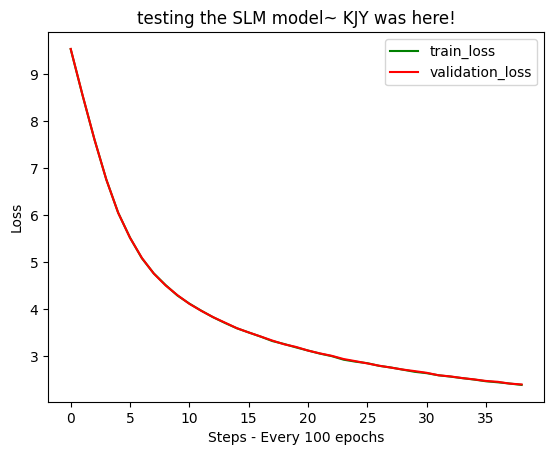

In [ ]:
import matplotlib.pyplot as plt
train_loss_list_converted = [i.cpu().detach() for i in train_loss_list]
validation_loss_list_converted = [i.cpu().detach() for i in validation_loss_list]

plt.title("testing the SLM model~ KJY was here!")
plt.plot(train_loss_list_converted, 'g', label='train_loss')
plt.plot(validation_loss_list_converted, 'r', label='validation_loss')
plt.xlabel("Steps - Every 100 epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()



Step 10: Run SLM Inference on our trained model

In [ ]:
#Load the model
model = GPT(config)  # re-create the model with same config
device =  "cuda" if torch.cuda.is_available() else "cpu"
best_model_params_path = "best_model_params.pt"
model.load_state_dict(torch.load(best_model_params_path, map_location=torch.device(device))) # load best model states


<All keys matched successfully>

In [ ]:
sentence = "Once upon a time there was a pumpkin."
context = (torch.tensor(enc.encode_ordinary(sentence)).unsqueeze(dim = 0))
y = model.generate(context, 200)
print(enc.decode(y.squeeze().tolist()))

Once upon a time there was a pumpkin. It was too high and it seemed to fly through.

One day a little girl named Polly was only three years old, so she wanted to accept yoga. She asked her mum, 2 laser soldiers, and she smiled and said, "Today, like to play."

Daisy stopped and said, "Mummy, why did you pat me dance so hard. Could you ride it?"

It smiled and said, "Yes!"gent and that became very well together, and alike. Rachel did quite use made it for a ride. 

WhenAlright, Hope knew she was sad and couldn't return to take thisFine.Once upon a time there was a naughty girl named Sarah. She was knew they had been playing in the garden. She would put it in her arms and point out her hands and twirling. It was a very delicious bird that she had mixed all the time. One day Sarah's mom decided she would come back back to her house and


In [ ]:
## this is my example (based on a true emotion ㅋㅋㅋㅋㅋ)
sentence = "I like studying math and wish to be good at it."
context = (torch.tensor(enc.encode_ordinary(sentence)).unsqueeze(dim = 0))
y = model.generate(context, 200)
print(enc.decode(y.squeeze().tolist()))

I like studying math and wish to be good at it. I don't give you to someone."

Lily was happy and she did. She began to smile and thanked herself for learning new places and sharing the time her mom gifted people.Once upon a time, there was a little girl named Lily. She had a pink camera that she had wore in new headphones and made sure stories were getting smaller and stronger. 

One day, Lily went to the park with her mommy. She saw her mommy act quickly, and felt scared. She ran to the note to her mommy, and put her paper on. Lily put her hat on her head, but it was too heavy and raining. 

As she hugged, she found a twig, blueberry Poo and it's shiny to teddy bear. She giggled as she started organizing her necklace and it scissors were sparkly and blooming the girl. 

In the end, - She was always able to be an expert she could have fun


In [ ]:
from google.colab import runtime
runtime.unassign()

In [ ]:
# @title
sentence = "A little girl went to the woods"
context = (torch.tensor(enc.encode_ordinary(sentence)).unsqueeze(dim = 0))
y = model.generate(context, 200)
print(enc.decode(y.squeeze().tolist()))

NameError: name 'torch' is not defined